# Tarea 1 – Parte 2: Modelado y clasificación de noticias

En esta sección se comparan tres enfoques para clasificar titulares de noticias:

1. Zero-Shot Classification.
2. Etiquetado mediante un LLM.
3. Transformer con fine-tuning.

In [1]:
from pathlib import Path
import pandas as pd

BASE_DIR = Path("tarea_1") if Path("tarea_1").exists() else Path(".")

ruta_datos = BASE_DIR / "datos" / "noticias.csv"

df = pd.read_csv(ruta_datos)

print("Dimensiones:", df.shape)
print("\nDistribución por categoría:")
print(df["etiqueta"].value_counts())

df.head()

Dimensiones: (400, 7)

Distribución por categoría:
etiqueta
politica              100
economia              100
deportes              100
ciencia_tecnologia    100
Name: count, dtype: int64


,titular,bajada,medio,seccion_original,url,fecha,etiqueta
0,''Evacúen sus casas desde ya'': Keiko Fujimori...,La mandataria mencionó que el fenómeno está af...,La República,politica,https://larepublica.pe/politica/2026/10/16/eva...,2026-10-16 07:52:00,politica
1,Keiko Fujimori sobre limpieza del río Piura an...,"Además, optó por darle la responsabilidad a la...",La República,politica,https://larepublica.pe/politica/2026/10/17/kei...,2026-10-17 08:36:31,politica
2,Debate de pedido de facultades sigue entrampad...,La Comisión de Constitución del Senado todavía...,La República,politica,https://larepublica.pe/politica/2026/10/17/deb...,2026-10-17 07:14:35,politica
3,Fuerza Popular desconoce votación que pedía de...,Cuatro bancadas de oposición abandonaron la se...,La República,politica,https://larepublica.pe/politica/2026/10/15/fue...,2026-10-15 19:05:12,politica
4,Solicitan la destitución de Roberto Burneo por...,"La asociación civil Iniciativa Democrática, or...",La República,politica,https://larepublica.pe/politica/2026/10/16/sol...,2026-10-16 14:54:58,politica


In [2]:
muestra_zero_shot = (
    df.groupby("etiqueta", group_keys=False)
      .sample(n=10, random_state=42)
      .reset_index(drop=True)
)

print("Tamaño de la muestra:", len(muestra_zero_shot))
print(muestra_zero_shot["etiqueta"].value_counts())

Tamaño de la muestra: 40
etiqueta
ciencia_tecnologia    10
deportes              10
economia              10
politica              10
Name: count, dtype: int64


In [3]:
import transformers
import torch
import sklearn

print(transformers.__version__)
print(torch.__version__)
print(sklearn.__version__)

c:\Users\Alvar\anaconda3\envs\webscraping\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


5.20.1
2.14.1+cpu
1.9.1


## 1. Clasificación Zero-Shot

Se utiliza un modelo Zero-Shot para clasificar una muestra balanceada de 40 titulares, sin realizar un entrenamiento previo con el dataset de noticias.

In [4]:
from transformers import pipeline
from sklearn.metrics import accuracy_score, f1_score

modelo_zero_shot = pipeline(
    "zero-shot-classification",
    model="Recognai/bert-base-spanish-wwm-cased-xnli",
    device=-1
)

categorias_modelo = [
    "política",
    "economía",
    "deportes",
    "ciencia y tecnología"
]

mapeo_prediccion = {
    "política": "politica",
    "economía": "economia",
    "deportes": "deportes",
    "ciencia y tecnología": "ciencia_tecnologia"
}

c:\Users\Alvar\anaconda3\envs\webscraping\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Alvar\.cache\huggingface\hub\models--Recognai--bert-base-spanish-wwm-cased-xnli. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\Alvar\anaconda3\envs\webscraping\Lib\site-packages\huggingface_hub\file_down

In [5]:
titular_prueba = muestra_zero_shot.loc[0, "titular"]

resultado = modelo_zero_shot(
    titular_prueba,
    candidate_labels=categorias_modelo,
    hypothesis_template="Este titular trata sobre {}."
)

print("Titular:", titular_prueba)
print("Etiqueta real:", muestra_zero_shot.loc[0, "etiqueta"])
print("Predicción:", resultado["labels"][0])
print("Confianza:", round(resultado["scores"][0], 3))

Titular: La humanidad roza sus límites: la población mundial alcanzaría los 12.400 millones en 2070, mientras científicos sugieren reducirla a 4.000 millones para 2200
Etiqueta real: ciencia_tecnologia
Predicción: ciencia y tecnología
Confianza: 0.737


In [6]:
predicciones = []

for titular in muestra_zero_shot["titular"]:
    resultado = modelo_zero_shot(
        titular,
        candidate_labels=categorias_modelo,
        hypothesis_template="Este titular trata sobre {}."
    )

    predicciones.append({
        "prediccion_zero_shot": mapeo_prediccion[resultado["labels"][0]],
        "confianza_zero_shot": resultado["scores"][0]
    })

df_predicciones = pd.DataFrame(predicciones)

muestra_zero_shot = pd.concat(
    [muestra_zero_shot, df_predicciones],
    axis=1
)

In [7]:
accuracy_zero = accuracy_score(
    muestra_zero_shot["etiqueta"],
    muestra_zero_shot["prediccion_zero_shot"]
)

f1_zero = f1_score(
    muestra_zero_shot["etiqueta"],
    muestra_zero_shot["prediccion_zero_shot"],
    average="macro"
)

print(f"Accuracy Zero-Shot: {accuracy_zero:.3f}")
print(f"F1 Macro Zero-Shot: {f1_zero:.3f}")

Accuracy Zero-Shot: 0.800
F1 Macro Zero-Shot: 0.791


### Revisión de errores del modelo Zero-Shot

Se identifican los titulares cuya categoría predicha no coincide con la etiqueta original para analizar los principales errores del modelo.

In [8]:
errores_zero_shot = muestra_zero_shot[
    muestra_zero_shot["etiqueta"] !=
    muestra_zero_shot["prediccion_zero_shot"]
][
    ["titular", "etiqueta", "prediccion_zero_shot", "confianza_zero_shot"]
]

print(f"Errores encontrados: {len(errores_zero_shot)}")
errores_zero_shot

Errores encontrados: 8


,titular,etiqueta,prediccion_zero_shot,confianza_zero_shot
14,Luis Carlos Arias Schreiber: “Si Alejandro Olm...,deportes,politica,0.808821
22,"Tras cuernos, palos, por Kurt Burneo",economia,deportes,0.714816
26,"BCRP mantiene tasa de referencia en 4,25% por ...",economia,politica,0.580930
27,Reinfo: formalización minera hasta 2028 exigir...,economia,politica,0.905171
28,Aeropuerto Jorge Chávez: LAP revela que aerolí...,economia,politica,0.349987
29,Inteligencia artificial para conseguir trabajo...,economia,ciencia_tecnologia,0.640933
30,Fugó cabecilla de la banda que mató a “China P...,politica,deportes,0.726629
37,Madre de Dios: Uno de los 3 abatidos en La Pam...,politica,deportes,0.351529


## 2. Etiquetado con LLM local

Se utiliza el modelo `qwen3:4b-instruct`, ejecutado localmente mediante Ollama, para clasificar los titulares del dataset completo en una de las cuatro categorías definidas.

In [9]:
import requests
import json

OLLAMA_URL = "http://localhost:11434/api/generate"
MODELO_LLM = "qwen3:4b-instruct"

respuesta = requests.get("http://localhost:11434/api/tags")

print("Conexión con Ollama:", respuesta.status_code)

Conexión con Ollama: 200


In [10]:
def clasificar_con_llm(titular):
    prompt = f"""
Clasifica el siguiente titular de noticia en UNA sola de estas categorías:

- politica
- economia
- deportes
- ciencia_tecnologia

Titular:
"{titular}"

Devuelve únicamente un JSON con esta estructura:

{{
  "etiqueta": "categoria",
  "confianza": 0.00
}}

La confianza debe ser un número entre 0 y 1.
No agregues explicaciones.
"""

    payload = {
        "model": MODELO_LLM,
        "prompt": prompt,
        "stream": False,
        "format": "json",
        "options": {
            "temperature": 0
        }
    }

    respuesta = requests.post(
        OLLAMA_URL,
        json=payload,
        timeout=120
    )

    respuesta.raise_for_status()

    contenido = respuesta.json()["response"]
    resultado = json.loads(contenido)

    return resultado

In [11]:
titular_prueba = df.loc[0, "titular"]

resultado_llm = clasificar_con_llm(titular_prueba)

print("Titular:", titular_prueba)
print("Etiqueta original:", df.loc[0, "etiqueta"])
print("Respuesta LLM:", resultado_llm)

Titular: ''Evacúen sus casas desde ya'': Keiko Fujimori pide a población que vive cerca a ríos que ''alisten su mochila'' ante El Niño
Etiqueta original: politica
Respuesta LLM: {'etiqueta': 'politica', 'confianza': 0.99}


### Etiquetado del dataset completo

Se aplica el LLM local a los 400 titulares. Los resultados se guardan progresivamente para evitar la pérdida del avance ante una interrupción del proceso.

In [12]:
from pathlib import Path
import pandas as pd
import time

ruta_llm = BASE_DIR / "datos" / "etiquetas_llm.csv"

# Recuperar avance previo si existe
if ruta_llm.exists():
    df_llm = pd.read_csv(ruta_llm)
    procesados = set(df_llm["titular"])
    resultados_llm = df_llm.to_dict("records")

    print(f"Se recuperaron {len(resultados_llm)} clasificaciones previas.")
else:
    procesados = set()
    resultados_llm = []

total = len(df)

for i, fila in df.iterrows():
    titular = fila["titular"]

    # Saltar noticias ya procesadas
    if titular in procesados:
        continue

    try:
        resultado = clasificar_con_llm(titular)

        resultados_llm.append({
            "titular": titular,
            "etiqueta_llm": resultado["etiqueta"],
            "confianza": resultado["confianza"],
            "modelo_llm": MODELO_LLM,
            "fecha": fila["fecha"]
        })

        procesados.add(titular)

        # Guardar progreso cada 10 noticias
        if len(resultados_llm) % 10 == 0:
            pd.DataFrame(resultados_llm).to_csv(
                ruta_llm,
                index=False,
                encoding="utf-8-sig"
            )

            print(
                f"Procesadas: {len(resultados_llm)}/{total}"
            )

    except Exception as e:
        print(f"Error en fila {i}: {e}")

    time.sleep(0.2)

# Guardado final
df_llm = pd.DataFrame(resultados_llm)

df_llm.to_csv(
    ruta_llm,
    index=False,
    encoding="utf-8-sig"
)

print("\nProceso terminado.")
print("Total etiquetado:", len(df_llm))
print("Archivo guardado en:", ruta_llm)

Procesadas: 10/400
Procesadas: 20/400
Procesadas: 30/400
Procesadas: 40/400
Procesadas: 50/400
Procesadas: 60/400
Procesadas: 70/400
Procesadas: 80/400
Procesadas: 90/400
Procesadas: 100/400
Procesadas: 110/400
Procesadas: 120/400
Procesadas: 130/400
Procesadas: 140/400
Procesadas: 150/400
Procesadas: 160/400
Procesadas: 170/400
Procesadas: 180/400
Procesadas: 190/400
Procesadas: 200/400
Procesadas: 210/400
Procesadas: 220/400
Procesadas: 230/400
Procesadas: 240/400
Procesadas: 250/400
Procesadas: 260/400
Procesadas: 270/400
Procesadas: 280/400
Procesadas: 290/400
Procesadas: 300/400
Procesadas: 310/400
Procesadas: 320/400
Procesadas: 330/400
Procesadas: 340/400
Procesadas: 350/400
Procesadas: 360/400
Procesadas: 370/400
Procesadas: 380/400
Procesadas: 390/400
Procesadas: 400/400

Proceso terminado.
Total etiquetado: 400
Archivo guardado en: datos\etiquetas_llm.csv


In [13]:
df_llm = pd.read_csv(BASE_DIR / "datos" / "etiquetas_llm.csv")

print("Dimensiones:", df_llm.shape)
print("\nEtiquetas generadas:")
print(df_llm["etiqueta_llm"].value_counts())

print("\nValores faltantes:")
print(df_llm.isna().sum())

Dimensiones: (400, 5)

Etiquetas generadas:
etiqueta_llm
politica              110
ciencia_tecnologia    108
deportes               99
economia               77
política                6
Name: count, dtype: int64

Valores faltantes:
titular         0
etiqueta_llm    0
confianza       0
modelo_llm      0
fecha           0
dtype: int64


## 3. Revisión manual de etiquetas del LLM

Se selecciona una muestra aleatoria de 20 titulares para revisar manualmente las etiquetas asignadas por el LLM y estimar el nivel de acuerdo humano-modelo.

In [14]:
muestra_revision = (
    df_llm
    .sample(n=20, random_state=42)
    .reset_index(drop=True)
)

muestra_revision[
    ["titular", "etiqueta_llm", "confianza"]
]

,titular,etiqueta_llm,confianza
0,"Daniel Prieto, arquero de Alianza Atlético, so...",deportes,0.990
1,LaLiga acompaña modernización del mítico Estad...,deportes,0.990
2,Segunda vuelta para la Municipalidad de Lima n...,politica,0.990
3,Antonio Rizola advierte sobre amenazas que rec...,deportes,0.990
4,Senado inicia debate sobre la desnaturalizació...,politica,0.990
5,Segunda vuelta regional: Somos Perú lidera en ...,politica,0.999
6,Un diente de elefante de 700.000 años de antig...,ciencia_tecnologia,0.990
7,Madre de Dios: Uno de los 3 abatidos en La Pam...,politica,0.990
8,"¿Qué partidos hay hoy, jueves 8 de octubre? Re...",deportes,0.990
9,Centros comerciales reciben 12% menos visitas ...,economia,0.980


In [15]:
for i, fila in muestra_revision.iterrows():
    print(f"{i}. {fila['titular']}")
    print(f"   LLM: {fila['etiqueta_llm']} | Confianza: {fila['confianza']}")
    print()

0. Daniel Prieto, arquero de Alianza Atlético, sobre cambio de localía para jugar ante Universitario: "Nos sacan de nuestra ciudad"
   LLM: deportes | Confianza: 0.99

1. LaLiga acompaña modernización del mítico Estadio Atanasio Girardot en Colombia: ¿pasará lo mismo en Perú?
   LLM: deportes | Confianza: 0.99

2. Segunda vuelta para la Municipalidad de Lima no es viable, aseguran expertos
   LLM: politica | Confianza: 0.99

3. Antonio Rizola advierte sobre amenazas que reciben jugadoras de la Liga Peruana de Vóley: "Las extranjeras no quieren venir"
   LLM: deportes | Confianza: 0.99

4. Senado inicia debate sobre la desnaturalización de dictámenes
   LLM: politica | Confianza: 0.99

5. Segunda vuelta regional: Somos Perú lidera en seis de las 15 regiones que definirán a sus gobernadores
   LLM: politica | Confianza: 0.999

6. Un diente de elefante de 700.000 años de antigüedad revela un ecosistema perdido que compartieron los primeros humanos
   LLM: ciencia_tecnologia | Confianza: 0

### Resultado de la auditoría humana

Se revisaron manualmente 20 predicciones seleccionadas al azar. En los 20 casos, la etiqueta asignada por el LLM coincidió con la revisión humana.

**Acuerdo humano-LLM: 20/20 = 100%.**

In [16]:
# Luego de la revisión manual, los 20 casos fueron confirmados
muestra_revision["etiqueta_manual"] = muestra_revision["etiqueta_llm"]

muestra_revision["acuerdo"] = (
    muestra_revision["etiqueta_llm"] ==
    muestra_revision["etiqueta_manual"]
)

acuerdo_llm = muestra_revision["acuerdo"].mean()

print(f"Coincidencias: {muestra_revision['acuerdo'].sum()}/20")
print(f"Acuerdo humano-LLM: {acuerdo_llm:.1%}")

Coincidencias: 20/20
Acuerdo humano-LLM: 100.0%


## 4. Preparación del dataset para modelado

Se integran las etiquetas generadas por el LLM con el dataset original. Para el entrenamiento supervisado se utiliza `etiqueta_llm` como variable objetivo, conservando la etiqueta original como referencia.

In [17]:
# Permite unir correctamente incluso si hubiera titulares repetidos
df_aux = df.copy()
df_llm_aux = df_llm.copy()

df_aux["_n"] = df_aux.groupby("titular").cumcount()
df_llm_aux["_n"] = df_llm_aux.groupby("titular").cumcount()

df_modelado = df_aux.merge(
    df_llm_aux[["titular", "_n", "etiqueta_llm", "confianza"]],
    on=["titular", "_n"],
    how="inner"
).drop(columns="_n")

print("Dimensiones:", df_modelado.shape)

df_modelado[
    ["titular", "etiqueta", "etiqueta_llm", "confianza"]
].head()

Dimensiones: (400, 9)


,titular,etiqueta,etiqueta_llm,confianza
0,''Evacúen sus casas desde ya'': Keiko Fujimori...,politica,politica,0.990
1,Keiko Fujimori sobre limpieza del río Piura an...,politica,politica,0.990
2,Debate de pedido de facultades sigue entrampad...,politica,politica,1.000
3,Fuerza Popular desconoce votación que pedía de...,politica,politica,0.990
4,Solicitan la destitución de Roberto Burneo por...,politica,politica,0.999


## 5. División Train / Validation / Test

El dataset se divide de manera estratificada en 70% para entrenamiento, 15% para validación y 15% para prueba, utilizando `random_state=42` para garantizar reproducibilidad.

El conjunto de test se mantiene aislado hasta la evaluación final.

In [18]:
from sklearn.model_selection import train_test_split

# 70% entrenamiento - 30% temporal
train_df, temp_df = train_test_split(
    df_modelado,
    test_size=0.30,
    stratify=df_modelado["etiqueta_llm"],
    random_state=42
)

# El 30% restante se divide en 15% validation y 15% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["etiqueta_llm"],
    random_state=42
)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (280, 9)
Validation: (60, 9)
Test: (60, 9)


In [19]:
print("TRAIN")
print(train_df["etiqueta_llm"].value_counts())

print("\nVALIDATION")
print(val_df["etiqueta_llm"].value_counts())

print("\nTEST")
print(test_df["etiqueta_llm"].value_counts())

TRAIN
etiqueta_llm
politica              77
ciencia_tecnologia    76
deportes              69
economia              54
política               4
Name: count, dtype: int64

VALIDATION
etiqueta_llm
politica              17
ciencia_tecnologia    16
deportes              15
economia              11
política               1
Name: count, dtype: int64

TEST
etiqueta_llm
politica              16
ciencia_tecnologia    16
deportes              15
economia              12
política               1
Name: count, dtype: int64


In [20]:
import unicodedata

def normalizar_etiqueta_llm(etiqueta):
    etiqueta = str(etiqueta).strip().lower()

    # Quitar tildes
    etiqueta = (
        unicodedata.normalize("NFKD", etiqueta)
        .encode("ascii", "ignore")
        .decode("ascii")
    )

    # Homogeneizar separadores
    etiqueta = etiqueta.replace(" ", "_").replace("-", "_")

    # Variantes posibles
    equivalencias = {
        "politica": "politica",
        "economia": "economia",
        "deportes": "deportes",
        "ciencia_tecnologia": "ciencia_tecnologia",
        "ciencia_y_tecnologia": "ciencia_tecnologia"
    }

    return equivalencias.get(etiqueta, etiqueta)


df_llm["etiqueta_llm"] = (
    df_llm["etiqueta_llm"]
    .apply(normalizar_etiqueta_llm)
)

In [21]:
print(df_llm["etiqueta_llm"].value_counts())
print("\nEtiquetas únicas:")
print(df_llm["etiqueta_llm"].unique())

etiqueta_llm
politica              116
ciencia_tecnologia    108
deportes               99
economia               77
Name: count, dtype: int64

Etiquetas únicas:
<StringArray>
['politica', 'economia', 'ciencia_tecnologia', 'deportes']
Length: 4, dtype: str


In [22]:
etiquetas_validas = {
    "politica",
    "economia",
    "deportes",
    "ciencia_tecnologia"
}

etiquetas_invalidas = (
    set(df_llm["etiqueta_llm"].unique())
    - etiquetas_validas
)

print("Etiquetas inválidas:", etiquetas_invalidas)

Etiquetas inválidas: set()


In [23]:
df_llm.to_csv(
    BASE_DIR / "datos" / "etiquetas_llm.csv",
    index=False,
    encoding="utf-8-sig"
)

print("etiquetas_llm.csv actualizado correctamente.")

etiquetas_llm.csv actualizado correctamente.


In [24]:
df_aux = df.copy()
df_llm_aux = df_llm.copy()

df_aux["_n"] = df_aux.groupby("titular").cumcount()
df_llm_aux["_n"] = df_llm_aux.groupby("titular").cumcount()

df_modelado = df_aux.merge(
    df_llm_aux[["titular", "_n", "etiqueta_llm", "confianza"]],
    on=["titular", "_n"],
    how="inner"
).drop(columns="_n")

print("Dimensiones:", df_modelado.shape)
print(df_modelado["etiqueta_llm"].value_counts())

Dimensiones: (400, 9)
etiqueta_llm
politica              116
ciencia_tecnologia    108
deportes               99
economia               77
Name: count, dtype: int64


In [26]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df_modelado,
    test_size=0.30,
    stratify=df_modelado["etiqueta_llm"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["etiqueta_llm"],
    random_state=42
)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (280, 9)
Validation: (60, 9)
Test: (60, 9)


In [27]:
print("TRAIN")
print(train_df["etiqueta_llm"].value_counts())

print("\nVALIDATION")
print(val_df["etiqueta_llm"].value_counts())

print("\nTEST")
print(test_df["etiqueta_llm"].value_counts())

TRAIN
etiqueta_llm
politica              81
ciencia_tecnologia    76
deportes              69
economia              54
Name: count, dtype: int64

VALIDATION
etiqueta_llm
politica              18
ciencia_tecnologia    16
deportes              15
economia              11
Name: count, dtype: int64

TEST
etiqueta_llm
politica              17
ciencia_tecnologia    16
deportes              15
economia              12
Name: count, dtype: int64


In [28]:
import torch

print("CUDA disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("El entrenamiento se realizará con CPU.")

CUDA disponible: False
El entrenamiento se realizará con CPU.


In [29]:
etiquetas = [
    "politica",
    "economia",
    "deportes",
    "ciencia_tecnologia"
]

label2id = {etiqueta: i for i, etiqueta in enumerate(etiquetas)}
id2label = {i: etiqueta for etiqueta, i in label2id.items()}

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["label"] = train_df["etiqueta_llm"].map(label2id)
val_df["label"] = val_df["etiqueta_llm"].map(label2id)
test_df["label"] = test_df["etiqueta_llm"].map(label2id)

label2id

{'politica': 0, 'economia': 1, 'deportes': 2, 'ciencia_tecnologia': 3}

In [30]:
from datasets import Dataset

train_ds = Dataset.from_pandas(
    train_df[["titular", "label"]].reset_index(drop=True)
)

val_ds = Dataset.from_pandas(
    val_df[["titular", "label"]].reset_index(drop=True)
)

test_ds = Dataset.from_pandas(
    test_df[["titular", "label"]].reset_index(drop=True)
)

print(train_ds)
print(val_ds)
print(test_ds)

Dataset({
    features: ['titular', 'label'],
    num_rows: 280
})
Dataset({
    features: ['titular', 'label'],
    num_rows: 60
})
Dataset({
    features: ['titular', 'label'],
    num_rows: 60
})


### Preparación del modelo y tokenización

Se utiliza `distilbert-base-multilingual-cased`, un Transformer multilingüe de menor tamaño, adecuado para realizar fine-tuning con recursos computacionales limitados.

In [31]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

modelo_base = "distilbert-base-multilingual-cased"

tokenizer = AutoTokenizer.from_pretrained(modelo_base)

model = AutoModelForSequenceClassification.from_pretrained(
    modelo_base,
    num_labels=4,
    id2label=id2label,
    label2id=label2id
)

c:\Users\Alvar\anaconda3\envs\webscraping\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Alvar\.cache\huggingface\hub\models--distilbert-base-multilingual-cased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 100/100 [00:00<00:00, 430.88it/s]
[transformers] DistilBert

In [32]:
def tokenizar(batch):
    return tokenizer(
        batch["titular"],
        truncation=True,
        padding="max_length",
        max_length=128
    )

train_tokenized = train_ds.map(tokenizar, batched=True)
val_tokenized = val_ds.map(tokenizar, batched=True)
test_tokenized = test_ds.map(tokenizar, batched=True)

Map: 100%|██████████| 60/60 [00:00<00:00, 3509.29 examples/s]


In [33]:
print(train_tokenized)
print(val_tokenized)

Dataset({
    features: ['titular', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 280
})
Dataset({
    features: ['titular', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 60
})


In [34]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

def calcular_metricas(eval_pred):
    logits, labels = eval_pred
    predicciones = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predicciones),
        "f1_macro": f1_score(
            labels,
            predicciones,
            average="macro"
        )
    }

In [37]:
import sys

print(sys.executable)

c:\Users\Alvar\anaconda3\envs\webscraping\python.exe


In [38]:
import sys
!{sys.executable} -m pip install -U "accelerate>=1.1.0"

In [1]:
import accelerate
print(accelerate.__version__)

1.15.0


c:\Users\Alvar\anaconda3\envs\webscraping\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from pathlib import Path
import pandas as pd
import unicodedata

from sklearn.model_selection import train_test_split
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification

BASE_DIR = Path("tarea_1") if Path("tarea_1").exists() else Path(".")

# Cargar archivos ya guardados
df = pd.read_csv(BASE_DIR / "datos" / "noticias.csv")
df_llm = pd.read_csv(BASE_DIR / "datos" / "etiquetas_llm.csv")

# Normalizar etiquetas del LLM
def normalizar_etiqueta_llm(etiqueta):
    etiqueta = str(etiqueta).strip().lower()

    etiqueta = (
        unicodedata.normalize("NFKD", etiqueta)
        .encode("ascii", "ignore")
        .decode("ascii")
    )

    etiqueta = etiqueta.replace(" ", "_").replace("-", "_")

    equivalencias = {
        "politica": "politica",
        "economia": "economia",
        "deportes": "deportes",
        "ciencia_tecnologia": "ciencia_tecnologia",
        "ciencia_y_tecnologia": "ciencia_tecnologia"
    }

    return equivalencias.get(etiqueta, etiqueta)

df_llm["etiqueta_llm"] = df_llm["etiqueta_llm"].apply(
    normalizar_etiqueta_llm
)

# Integrar dataset original + etiquetas LLM
df_aux = df.copy()
df_llm_aux = df_llm.copy()

df_aux["_n"] = df_aux.groupby("titular").cumcount()
df_llm_aux["_n"] = df_llm_aux.groupby("titular").cumcount()

df_modelado = df_aux.merge(
    df_llm_aux[["titular", "_n", "etiqueta_llm", "confianza"]],
    on=["titular", "_n"],
    how="inner"
).drop(columns="_n")

# Split 70 / 15 / 15
train_df, temp_df = train_test_split(
    df_modelado,
    test_size=0.30,
    stratify=df_modelado["etiqueta_llm"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["etiqueta_llm"],
    random_state=42
)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (280, 9)
Validation: (60, 9)
Test: (60, 9)


In [3]:
etiquetas = [
    "politica",
    "economia",
    "deportes",
    "ciencia_tecnologia"
]

label2id = {etiqueta: i for i, etiqueta in enumerate(etiquetas)}
id2label = {i: etiqueta for etiqueta, i in label2id.items()}

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["label"] = train_df["etiqueta_llm"].map(label2id)
val_df["label"] = val_df["etiqueta_llm"].map(label2id)
test_df["label"] = test_df["etiqueta_llm"].map(label2id)

train_ds = Dataset.from_pandas(
    train_df[["titular", "label"]].reset_index(drop=True)
)

val_ds = Dataset.from_pandas(
    val_df[["titular", "label"]].reset_index(drop=True)
)

test_ds = Dataset.from_pandas(
    test_df[["titular", "label"]].reset_index(drop=True)
)

modelo_base = "distilbert-base-multilingual-cased"

tokenizer = AutoTokenizer.from_pretrained(modelo_base)

model = AutoModelForSequenceClassification.from_pretrained(
    modelo_base,
    num_labels=4,
    id2label=id2label,
    label2id=label2id
)

def tokenizar(batch):
    return tokenizer(
        batch["titular"],
        truncation=True,
        padding="max_length",
        max_length=128
    )

train_tokenized = train_ds.map(tokenizar, batched=True)
val_tokenized = val_ds.map(tokenizar, batched=True)
test_tokenized = test_ds.map(tokenizar, batched=True)

print(train_tokenized)
print(val_tokenized)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 390.72it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
Map: 100%|██████████| 60/60 [00:00<00:00, 3681.58 examples/s]

Dataset({
    features: ['titular', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 280
})
Dataset({
    features: ['titular', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 60
})


In [4]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

def calcular_metricas(eval_pred):
    logits, labels = eval_pred
    predicciones = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predicciones),
        "f1_macro": f1_score(
            labels,
            predicciones,
            average="macro"
        )
    }

In [5]:
from transformers import TrainingArguments, Trainer

training_args = TrainingArguments(
    output_dir=str(BASE_DIR / "modelo" / "distilbert_noticias"),
    
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=3,
    weight_decay=0.01,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,

    save_total_limit=1,
    report_to="none"
)

In [6]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=val_tokenized,
    compute_metrics=calcular_metricas
)

In [7]:
resultado_entrenamiento = trainer.train()

c:\Users\Alvar\anaconda3\envs\webscraping\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,No log,0.873051,0.800000,0.763640
2,No log,0.507855,0.866667,0.861349
3,No log,0.434308,0.866667,0.861349


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.24s/it]
c:\Users\Alvar\anaconda3\envs\webscraping\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.13s/it]
c:\Users\Alvar\anaconda3\envs\webscraping\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.77it/s]


In [8]:
import pandas as pd

historial = pd.DataFrame(trainer.state.log_history)
historial

,eval_loss,eval_accuracy,eval_f1_macro,eval_runtime,eval_samples_per_second,eval_steps_per_second,epoch,step,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,0.873051,0.800000,0.763640,4.1060,14.613,1.948,1.0,35,NaN,NaN,NaN,NaN,NaN
1,0.507855,0.866667,0.861349,4.0956,14.650,1.953,2.0,70,NaN,NaN,NaN,NaN,NaN
2,0.434308,0.866667,0.861349,3.9490,15.194,2.026,3.0,105,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,3.0,105,349.5451,2.403,0.3,2.781915e+13,0.732316


In [9]:
historial_metricas = historial[
    historial["eval_accuracy"].notna()
][[
    "epoch",
    "eval_loss",
    "eval_accuracy",
    "eval_f1_macro"
]]

historial_metricas

,epoch,eval_loss,eval_accuracy,eval_f1_macro
0,1.0,0.873051,0.800000,0.763640
1,2.0,0.507855,0.866667,0.861349
2,3.0,0.434308,0.866667,0.861349


In [10]:
metricas_test = trainer.evaluate(
    test_tokenized,
    metric_key_prefix="test"
)

metricas_test

c:\Users\Alvar\anaconda3\envs\webscraping\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
No log,0.482227,3,0.900000,0.904241


{'test_loss': 0.4822269678115845,
 'test_accuracy': 0.9,
 'test_f1_macro': 0.9042405880393136}

In [12]:
import sys
!{sys.executable} -m pip install matplotlib

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.3 MB 4.2 MB/s eta 0:00:03
   ----- ---------------------------------- 1.3/9.3 MB 4.8 MB/s eta 0:00:02
   -------- ------------------------------- 2.1/9.3 MB 3.5 MB/s eta 0:00:03
   --------------- ------------------------ 3.7/9.3 MB 4.5 MB/s eta 0:00:02
   -------------------- ------------------- 4.7/9.3 MB 4.5 MB/s eta 0:00:02
   ----------------------------- ---------- 6.8/9.3 MB 5.4 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 6.4 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 6.3 MB/s  0:00:01
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ------------------------------------- -- 2.4/2.5 MB 12.3 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 11.0 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   --------------- ------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [13]:
import matplotlib.pyplot as plt
print("Matplotlib instalado correctamente")

Matplotlib instalado correctamente


c:\Users\Alvar\anaconda3\envs\webscraping\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


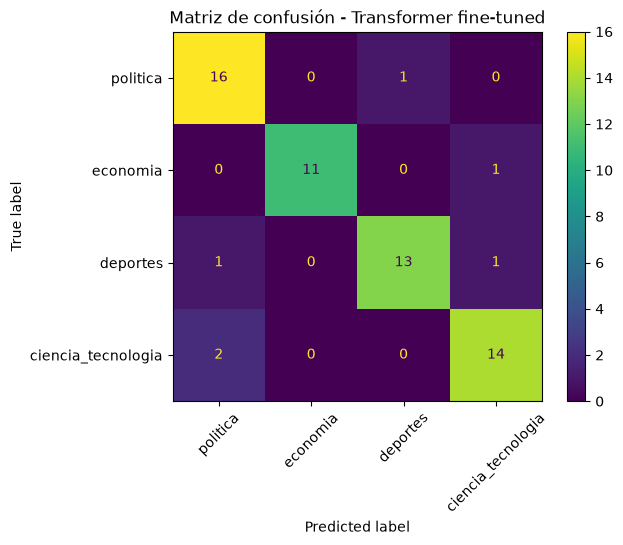

In [14]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

predicciones_test = trainer.predict(test_tokenized)

y_true = predicciones_test.label_ids
y_pred = np.argmax(predicciones_test.predictions, axis=-1)

cm = confusion_matrix(y_true, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=etiquetas
)

display.plot(xticks_rotation=45)

plt.title("Matriz de confusión - Transformer fine-tuned")
plt.show()

In [15]:
from sklearn.metrics import classification_report

reporte = classification_report(
    y_true,
    y_pred,
    target_names=etiquetas,
    digits=3
)

print(reporte)

                    precision    recall  f1-score   support

          politica      0.842     0.941     0.889        17
          economia      1.000     0.917     0.957        12
          deportes      0.929     0.867     0.897        15
ciencia_tecnologia      0.875     0.875     0.875        16

          accuracy                          0.900        60
         macro avg      0.911     0.900     0.904        60
      weighted avg      0.904     0.900     0.901        60



In [17]:
from sklearn.metrics import accuracy_score, f1_score

# Etiquetas originales del conjunto Test
y_true_original = (
    test_df["etiqueta"]
    .map(label2id)
    .to_numpy()
)

# --------------------------
# 1. LLM Qwen
# --------------------------

y_pred_llm = (
    test_df["etiqueta_llm"]
    .map(label2id)
    .to_numpy()
)

accuracy_llm = accuracy_score(
    y_true_original,
    y_pred_llm
)

f1_llm = f1_score(
    y_true_original,
    y_pred_llm,
    average="macro"
)

# --------------------------
# 2. Transformer fine-tuned
# --------------------------

accuracy_transformer = accuracy_score(
    y_true_original,
    y_pred
)

f1_transformer = f1_score(
    y_true_original,
    y_pred,
    average="macro"
)

print("LLM Qwen")
print("Accuracy:", round(accuracy_llm, 3))
print("F1 Macro:", round(f1_llm, 3))

print("\nTransformer fine-tuned")
print("Accuracy:", round(accuracy_transformer, 3))
print("F1 Macro:", round(f1_transformer, 3))

LLM Qwen
Accuracy: 0.933
F1 Macro: 0.933

Transformer fine-tuned
Accuracy: 0.9
F1 Macro: 0.901


In [18]:
from transformers import pipeline
from sklearn.metrics import accuracy_score, f1_score

modelo_zero_shot = "Recognai/bert-base-spanish-wwm-cased-xnli"

clasificador_zero_shot = pipeline(
    "zero-shot-classification",
    model=modelo_zero_shot,
    device=-1
)

etiquetas_candidatas = [
    "política",
    "economía",
    "deportes",
    "ciencia y tecnología"
]

mapa_etiquetas = {
    "política": "politica",
    "economía": "economia",
    "deportes": "deportes",
    "ciencia y tecnología": "ciencia_tecnologia"
}

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 303.09it/s]


In [19]:
resultados_zero_shot = clasificador_zero_shot(
    test_df["titular"].tolist(),
    candidate_labels=etiquetas_candidatas,
    hypothesis_template="Este titular trata sobre {}.",
    multi_label=False,
    batch_size=8
)

pred_zero_shot = [
    mapa_etiquetas[resultado["labels"][0]]
    for resultado in resultados_zero_shot
]

y_pred_zero_shot = [
    label2id[etiqueta]
    for etiqueta in pred_zero_shot
]

accuracy_zero_shot = accuracy_score(
    y_true_original,
    y_pred_zero_shot
)

f1_zero_shot = f1_score(
    y_true_original,
    y_pred_zero_shot,
    average="macro"
)

print("Zero-Shot")
print("Accuracy:", round(accuracy_zero_shot, 3))
print("F1 Macro:", round(f1_zero_shot, 3))

Zero-Shot
Accuracy: 0.733
F1 Macro: 0.731


In [20]:
comparacion_modelos = pd.DataFrame({
    "Modelo": [
        "Zero-Shot",
        "Qwen LLM",
        "DistilBERT fine-tuned"
    ],
    "Accuracy": [
        accuracy_zero_shot,
        accuracy_llm,
        accuracy_transformer
    ],
    "F1 Macro": [
        f1_zero_shot,
        f1_llm,
        f1_transformer
    ]
})

comparacion_modelos.round(3)

,Modelo,Accuracy,F1 Macro
0,Zero-Shot,0.733,0.731
1,Qwen LLM,0.933,0.933
2,DistilBERT fine-tuned,0.900,0.901


### Comparación final de modelos

Los tres enfoques fueron evaluados sobre el mismo conjunto de prueba de 60 noticias, utilizando como referencia la categoría original de La República.

- **Qwen LLM** obtuvo el mejor desempeño, con un Accuracy y F1 Macro de 0.933.
- **DistilBERT fine-tuned** alcanzó un Accuracy de 0.900 y un F1 Macro de 0.901, mostrando que el modelo logró aprender adecuadamente a partir de las etiquetas generadas por el LLM.
- **Zero-Shot** obtuvo los resultados más bajos, con un Accuracy de 0.733 y un F1 Macro de 0.731.

En consecuencia, el etiquetado mediante LLM presentó el mejor rendimiento sobre este conjunto de prueba, mientras que el Transformer fine-tuned obtuvo resultados cercanos utilizando un modelo más pequeño y especializado en la tarea.